# 8. Manuscript figures

Gathers the figures of the article, sized for the columns of *Acta Acustica*. Figures 2 and 3a repeat the calculation
of notebook 03 (long windows and mode catalogue); the others are drawn from the tables of notebooks 03–07. Output:
`results/manuscript_figures/`. (The photographic figure of the stone and its zones is composed from photographs and
views of the 3D model and is not generated here.)

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # folder with config.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as C
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.4})
pd.set_option("display.precision", 2)

from scipy import signal
from scipy.io import wavfile
warnings.filterwarnings("ignore", category=wavfile.WavFileWarning)
FS = C.FS; T = C.TABLES
OUT = C.RESULTS / "manuscript_figures"; OUT.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 9, "axes.grid": True, "grid.color": "0.85", "grid.alpha": 1.0, "savefig.dpi": 300,
                     "pdf.fonttype": 42, "ps.fonttype": 42})  # fonts embedded as TrueType; no transparency (EPS-safe)
W1, W2 = 3.5, 7.2   # width of one and two columns (inches)
def save_fig(name):
    for ext in ("pdf", "eps", "png"):
        plt.savefig(OUT / f"{name}.{ext}", bbox_inches="tight")
    plt.show()

## Mean spectrum and global modes (repeats the calculation of notebook 03)

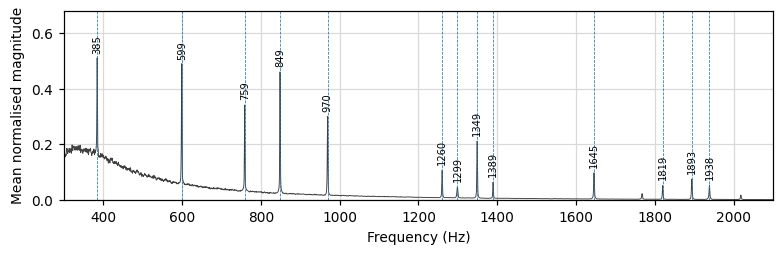

In [2]:
strikes = pd.read_csv(C.INTERMEDIATE / "strikes.csv").rename(columns={"i_peak": "i"})
strikes = strikes[strikes.set == "characterisation"].reset_index(drop=True)   # characterisation set
b_hp, a_hp = signal.butter(C.FILTER_ORDER, C.HIGHPASS_HZ / (0.5 * FS), btype="high")
b_hf, a_hf = signal.butter(4, 4000 / (0.5 * FS), btype="high")
sig, onsets = {}, {}
for w in strikes.file.unique():
    _, x = wavfile.read(C.AUDIO / w); xf = signal.filtfilt(b_hp, a_hp, x.astype(np.float32).mean(axis=1))
    env = signal.convolve(np.abs(signal.filtfilt(b_hf, a_hf, xf)), np.ones(96) / 96, "same")
    pk, _ = signal.find_peaks(env, height=15 * 1.4826 * np.median(env), distance=int(0.15 * FS)); sig[w], onsets[w] = xf, pk
def free_window(r):
    o = onsets[r.file]; s = o[o > r.i + int(0.1 * FS)]
    return ((s[0] if len(s) else len(sig[r.file])) - r.i) / FS - 0.02
strikes["window_s"] = strikes.apply(free_window, axis=1).clip(upper=2.0)
N = 2 ** 18; f = np.fft.rfftfreq(N, 1 / FS); band = (f > C.HIGHPASS_HZ) & (f < 3000); spec = []
for _, r in strikes.iterrows():
    L = int(r.window_s * FS); s = sig[r.file][r.i:r.i + L]; X = np.abs(np.fft.rfft(s * np.hanning(L), N)); spec.append((X / X[band].max()).astype(np.float32))
mean = np.mean(spec, axis=0)
tm = pd.read_csv(T / "t06_mode_table.csv")
fig, ax = plt.subplots(figsize=(W2, 2.4))
ax.plot(f[band], mean[band], lw=.6, color="0.25")
for m in tm.f_mean_Hz:
    ax.axvline(m, color="C0", ls="--", lw=.5)
for m, y in zip(tm.f_mean_Hz, np.interp(tm.f_mean_Hz, f, mean)):
    ax.text(m, y + .02, f"{m:.0f}", rotation=90, ha="center", va="bottom", fontsize=6.5)
ax.set_xlim(300, 2100); ax.set_ylim(0, .68); ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Mean normalised magnitude")
plt.tight_layout(); save_fig("fig2_mean_spectrum_modes")

## Decay of one strike and Q per mode

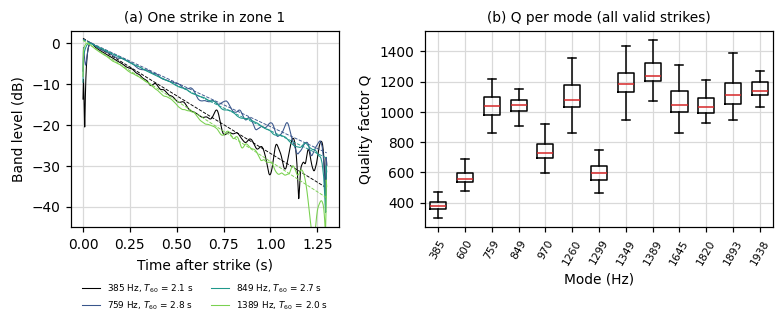

In [3]:
dg = pd.read_csv(T / "t03_damping_strikes.csv"); v = dg[dg.valid]
h = v[v.zone == 1].groupby("strike").size().idxmax()      # strike of zone 1 with the most measured modes
r = strikes[(strikes.zone == 1) & (strikes.strike == h)].iloc[0]
L = int(r.window_s * FS); seg = sig[r.file][r.i:r.i + L]; t = np.arange(L) / FS
fig, ax = plt.subplots(1, 2, figsize=(W2, 3.2), gridspec_kw={"width_ratios": [1, 1.3]})
sel = v[(v.zone == 1) & (v.strike == h)]
cols = plt.cm.viridis(np.linspace(0.0, 0.8, len(sel)))
cols[0] = (0, 0, 0, 1)                                     # darkest first: black     # increasing lightness: distinguishable in grey levels
for (_, m), col in zip(sel.iterrows(), cols):
    sos = signal.butter(2, [m.f - 15, m.f + 15], "bandpass", fs=FS, output="sos")
    env = signal.convolve(np.abs(signal.hilbert(signal.sosfiltfilt(sos, seg))), np.ones(240) / 240, "same")
    e = 20 * np.log10(env / env[int(0.02 * FS):int(0.15 * FS)].max() + 1e-12)
    ax[0].plot(t, e, lw=.7, color=col, label=f"{m.f:.0f} Hz, $T_{{60}}$ = {m.T60:.1f} s")
    ax[0].plot(t, -60 * t / m.T60 + (e[int(0.05 * FS)] + 60 * 0.05 / m.T60), "--", color=col, lw=.6)
ax[0].set_ylim(-45, 3); ax[0].set_xlabel("Time after strike (s)"); ax[0].set_ylabel("Band level (dB)")
ax[0].legend(fontsize=5.8, loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2, frameon=False)   # legend below the panel
ax[0].set_title("(a) One strike in zone 1", fontsize=9)
order = sorted(v["mode"].unique())
ax[1].boxplot([v[v["mode"] == m].Q for m in order], positions=range(len(order)), widths=.6, showfliers=False,
              medianprops={"color": "C3"})
ax[1].set_xticks(range(len(order))); ax[1].set_xticklabels([f"{m:.0f}" for m in order], rotation=60, fontsize=7)
ax[1].set_xlabel("Mode (Hz)"); ax[1].set_ylabel("Quality factor Q"); ax[1].set_title("(b) Q per mode (all valid strikes)", fontsize=9)
plt.tight_layout(); save_fig("fig3_decay_Q")

## Variance partition of the spectral features

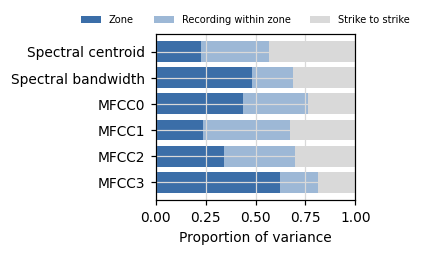

In [4]:
vc = pd.read_csv(T / "t05_variance_components.csv")
names = {"Centroid (Hz)": "Spectral centroid", "Bandwidth (Hz)": "Spectral bandwidth"}
vc["var"] = vc.variable.map(lambda s: names.get(s, s))
fig, ax = plt.subplots(figsize=(W1, 2.4))
y = np.arange(len(vc))[::-1]
ax.barh(y, vc.zone, color="#3b6ea8", label="Zone")
ax.barh(y, vc.recording, left=vc.zone, color="#9db8d6", label="Recording within zone")
ax.barh(y, vc.strike, left=vc.zone + vc.recording, color="#d9d9d9", label="Strike to strike")
ax.set_yticks(y); ax.set_yticklabels(vc["var"]); ax.set_xlim(0, 1); ax.set_xlabel("Proportion of variance")
ax.legend(fontsize=6.5, loc="lower center", bbox_to_anchor=(0.45, 1.0), ncol=3, frameon=False)
plt.tight_layout(); save_fig("fig4_variance_partition")

## Distance to the edge versus timbre

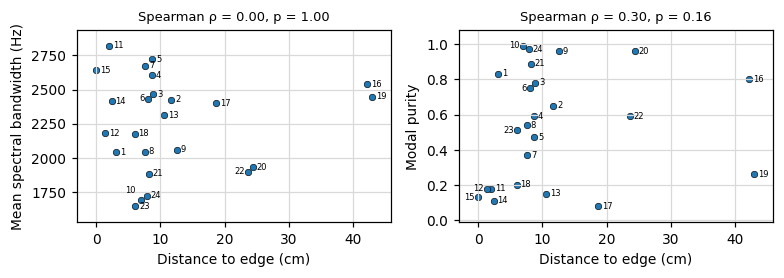

In [5]:
xy = pd.read_csv(C.COORDINATES)
z = (pd.read_csv(C.INTERMEDIATE / "features.csv").query("set == 'characterisation'").groupby("zone")
       .spectral_bandwidth.mean().rename("spectral_bandwidth_mean").reset_index())
pm = pd.read_csv(T / "t04_modal_amplitude_per_zone.csv")
d = xy.merge(z, on="zone").merge(pm[["zone", "modal_purity"]], on="zone")
bt = pd.read_csv(T / "t04_edge_vs_timbre.csv").set_index("variable")
fig, ax = plt.subplots(1, 2, figsize=(W2, 2.6))
for a, c, lab, key in [(ax[0], "spectral_bandwidth_mean", "Mean spectral bandwidth (Hz)", "Mean bandwidth"),
                       (ax[1], "modal_purity", "Modal purity", "Modal purity")]:
    a.scatter(100 * d.edge_distance_m, d[c], s=18, color="C0", edgecolor="k", lw=.4)
    a.set_xlabel("Distance to edge (cm)"); a.set_ylabel(lab)
    rho = round(bt.loc[key, "spearman_rho"], 2) + 0.0          # avoids "-0.00"
    a.set_title(f"Spearman ρ = {rho:.2f}, p = {bt.loc[key, 'p']:.2f}", fontsize=8.5)
plt.tight_layout(); fig.canvas.draw()
# zone labels placed so that they overlap neither each other nor the markers
cand = [(2, 0.5), (2, -6), (-2, 0.5), (-2, -6), (2.5, -2.7), (-2.5, -2.7), (-1.5, 2.2), (-1.5, -7.7), (4, 3), (4, -9), (-4, 3), (-4, -9)]
for a, c in [(ax[0], "spectral_bandwidth_mean"), (ax[1], "modal_purity")]:
    a.margins(x=0.07, y=0.1); fig.canvas.draw()
    pts = a.transData.transform(np.c_[100 * d.edge_distance_m, d[c]])
    pt2px = fig.dpi / 72
    marks = [(x - 2.3 * pt2px, y - 2.3 * pt2px, x + 2.3 * pt2px, y + 2.3 * pt2px) for x, y in pts]
    placed = []
    def free(b):
        return all(b[2] < o[0] or b[0] > o[2] or b[3] < o[1] or b[1] > o[3] for o in placed + marks)
    for (x, y), z, xd, yd in sorted(zip(pts, d.zone, 100 * d.edge_distance_m, d[c]), key=lambda q: q[0][0]):
        w, hgt = 3.2 * len(str(int(z))) * pt2px, 4.2 * pt2px
        for dx, dy in cand:
            x0 = x + dx * pt2px - (w if dx < 0 else 0)
            b = (x0, y + dy * pt2px, x0 + w, y + dy * pt2px + hgt)
            if free(b): break
        placed.append(b)
        a.annotate(str(int(z)), (xd, yd), xytext=((b[0] - x) / pt2px, (b[1] - y) / pt2px), textcoords="offset points",
                   fontsize=5.5, va="bottom", ha="left")
save_fig("fig5_edge_distance")

## Zone classifier: random split, leave one recording out and validation recordings

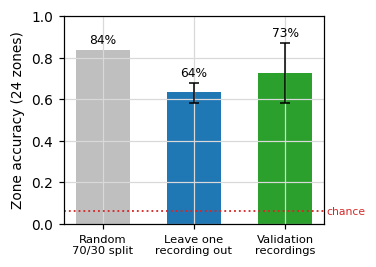

In [6]:
r = pd.read_csv(T / "t07_validation.csv").iloc[0]
fig, ax = plt.subplots(figsize=(W1, 2.5))
vals = [r.random_70_30, r.leave_one_recording_out, r.validation_accuracy]
tops = list(vals)
for i, (val, ci) in enumerate([(r.leave_one_recording_out, r.leave_one_recording_out_CI95), (r.validation_accuracy, r.validation_CI95)], start=1):
    lo, hi = map(float, ci.split("-")); tops[i] = hi
    ax.errorbar(i, val, yerr=[[val - lo], [hi - val]], color="k", capsize=3, lw=1, zorder=3)
ax.bar(range(3), vals, color=["0.75", "C0", "C2"], width=.6)
ax.axhline(r.chance_p95, color="C3", ls=":", lw=1.2)
ax.text(1.01, r.chance_p95, "chance", transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=7, color="C3")
for i, val in enumerate(vals): ax.text(i, tops[i] + .03, f"{val:.0%}", ha="center", fontsize=8)
ax.set_xticks(range(3)); ax.set_xticklabels(["Random\n70/30 split", "Leave one\nrecording out", "Validation\nrecordings"], fontsize=7.5)
ax.set_ylim(0, 1.0); ax.set_ylabel("Zone accuracy (24 zones)")
plt.tight_layout(); save_fig("fig6_classifier")

## Replication: modal frequencies in February and October

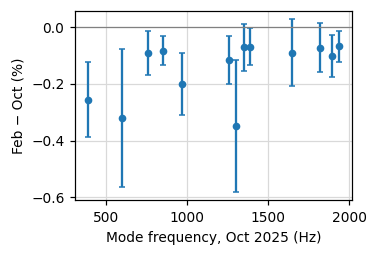

In [7]:
rep = pd.read_csv(T / "t06_replication.csv")
fig, ax = plt.subplots(figsize=(W1, 2.4))
ax.errorbar(rep.f_oct_Hz, 100 * rep.diff_Hz / rep.f_oct_Hz, yerr=100 * rep.sd_feb_Hz / rep.f_oct_Hz, fmt="o", ms=4, capsize=2, color="C0")
ax.axhline(0, color="0.5", lw=.8); ax.set_xlabel("Mode frequency, Oct 2025 (Hz)"); ax.set_ylabel("Feb − Oct (%)")
plt.tight_layout(); save_fig("fig7_replication")

## Conceptual model of the study

Outline of the work, from the data to the results (columns: data → processing → analysis of questions Q1–Q4 →
results). The figures in the last column are those of the article (notebooks 03–09).

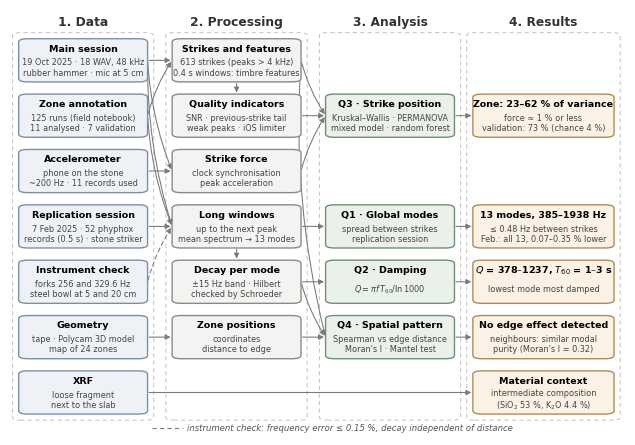

In [8]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
L = dict(cols=["1. Data", "2. Processing", "3. Analysis", "4. Results"],
  d_audio=("Main session", "19 Oct 2025 · 18 WAV, 48 kHz\nrubber hammer · mic at 5 cm"),
  d_ann=("Zone annotation", "125 runs (field notebook)\n11 analysed · 7 validation"),
  d_acc=("Accelerometer", "phone on the stone\n~200 Hz · 11 records used"),
  d_feb=("Replication session", "7 Feb 2025 · 52 phyphox\nrecords (0.5 s) · stone striker"),
  d_fork=("Instrument check", "forks 256 and 329.6 Hz\nsteel bowl at 5 and 20 cm"),
  d_geo=("Geometry", "tape · Polycam 3D model\nmap of 24 zones"),
  d_xrf=("XRF", "loose fragment\nnext to the slab"),
  p_seg=("Strikes and features", "613 strikes (peaks > 4 kHz)\n0.4 s windows: timbre features"),
  p_qc=("Quality indicators", "SNR · previous-strike tail\nweak peaks · iOS limiter"),
  p_force=("Strike force", "clock synchronisation\npeak acceleration"),
  p_long=("Long windows", "up to the next peak\nmean spectrum → 13 modes"),
  p_dec=("Decay per mode", "±15 Hz band · Hilbert\nchecked by Schroeder"),
  p_coord=("Zone positions", "coordinates\ndistance to edge"),
  a1=("Q1 · Global modes", "spread between strikes\nreplication session"),
  a2=("Q2 · Damping", r"$Q = \pi f\,T_{60} / \ln 1000$"),
  a3=("Q3 · Strike position", "Kruskal–Wallis · PERMANOVA\nmixed model · random forest"),
  a4=("Q4 · Spatial pattern", "Spearman vs edge distance\nMoran's I · Mantel test"),
  r1=("13 modes, 385–1938 Hz", "≤ 0.48 Hz between strikes\nFeb.: all 13, 0.07–0.35 % lower"),
  r2=(r"$Q$ = 378–1237, $T_{60}$ = 1–3 s", "lowest mode most damped"),
  r3=("Zone: 23–62 % of variance", "force ≈ 1 % or less\nvalidation: 73 % (chance 4 %)"),
  r4=("No edge effect detected", "neighbours: similar modal\npurity (Moran's I = 0.32)"),
  r5=("Material context", "intermediate composition\n" r"(SiO$_2$ 53 %, K$_2$O 4.4 %)"),
  check="instrument check: frequency error ≤ 0.15 %, decay independent of distance")
COLS = {"d": ("#eef2f7", "#7a8fa6"), "p": ("#f3f3f1", "#8a8a84"), "a": ("#e9f1ea", "#6f8f74"), "r": ("#fbf1e4", "#b08a55")}
XC = {"d": 0.0, "p": 1.0, "a": 2.0, "r": 3.0}; WB = {"d": 0.84, "p": 0.84, "a": 0.84, "r": 0.92}; HB = 0.78
POS = {"d_audio": 7.2, "d_ann": 6.2, "d_acc": 5.2, "d_feb": 4.2, "d_fork": 3.2, "d_geo": 2.2, "d_xrf": 1.2,
       "p_seg": 7.2, "p_qc": 6.2, "p_force": 5.2, "p_long": 4.2, "p_dec": 3.2, "p_coord": 2.2,
       "a3": 6.2, "a1": 4.2, "a2": 3.2, "a4": 2.2,
       "r3": 6.2, "r1": 4.2, "r2": 3.2, "r4": 2.2, "r5": 1.2}
ARROWS = [("d_audio", "p_seg"), ("d_ann", "p_seg"), ("d_audio", "p_long"), ("d_ann", "p_long"), ("d_audio", "p_force"),
          ("d_acc", "p_force"), ("d_feb", "p_long"), ("d_fork", "p_long", "--"), ("p_seg", "p_qc"), ("p_long", "p_dec"),
          ("d_geo", "p_coord"), ("p_seg", "a3"), ("p_qc", "a3"), ("p_force", "a3"), ("p_long", "a1"), ("p_dec", "a2"),
          ("p_seg", "a4"), ("p_dec", "a4"), ("p_coord", "a4"),
          ("a3", "r3"), ("a1", "r1"), ("a2", "r2"), ("a4", "r4"), ("d_xrf", "r5")]

fig, ax = plt.subplots(figsize=(W2, 5.0)); ax.set_xlim(-0.47, 3.53); ax.set_ylim(0.45, 8.1); ax.axis("off")
for i, k in enumerate("dpar"):
    w = WB[k] / 2 + 0.04
    ax.add_patch(FancyBboxPatch((XC[k] - w, 0.70), 2 * w, 7.0, boxstyle="round,pad=0,rounding_size=0.05",
                                fc="none", ec="#c8c8c8", ls=(0, (4, 3)), lw=0.7))
    ax.text(XC[k], 7.9, L["cols"][i], ha="center", va="center", fontsize=8, fontweight="bold", color="#333333")
ctr = {}
for k, y in POS.items():
    t = k[0]; fc, ec = COLS[t]; x = XC[t]; w = WB[t]; title, sub = L[k]
    ax.add_patch(FancyBboxPatch((x - w / 2, y - HB / 2), w, HB, boxstyle="round,pad=0,rounding_size=0.06",
                                fc=fc, ec=ec, lw=0.9, zorder=2))
    ax.text(x, y + 0.21, title, ha="center", va="center", fontsize=6.2, fontweight="bold", zorder=3)
    ax.text(x, y - 0.13, sub, ha="center", va="center", fontsize=5.3, color="#444444", linespacing=1.15, zorder=3)
    ctr[k] = (x, y)
for e in ARROWS:
    a, b = e[0], e[1]; ls = (0, (4, 3)) if len(e) > 2 else "-"
    (xa, ya), (xb, yb) = ctr[a], ctr[b]
    if abs(xa - xb) < 1e-6:                       # same column: vertical arrow
        p0, p1, rad = (xa, ya - HB / 2), (xb, yb + HB / 2), 0
    else:
        p0, p1 = (xa + WB[a[0]] / 2, ya), (xb - WB[b[0]] / 2, yb)
        rad = 0 if abs(ya - yb) < 1e-6 else 0.08 * (1 if yb < ya else -1)
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle="-|>", mutation_scale=7, color="#7a7a7a", lw=0.7, ls=ls,
                                 connectionstyle=f"arc3,rad={rad}", zorder=1, shrinkA=1, shrinkB=1))
ax.plot([0.45, 0.65], [0.55, 0.55], ls=(0, (4, 3)), color="#7a7a7a", lw=0.7)
ax.text(0.68, 0.55, L["check"], va="center", fontsize=5.6, style="italic", color="#555555")
save_fig("fig0_conceptual_model")